# Human Activity Recognition
## Modelado y Clasificación con Random Forest: División Estratificada y Escalamiento

Este notebook implementa la fase de preparación de datos para el modelado supervisado y el entrenamiento del clasificador **Random Forest** a partir del conjunto de características extraídas en `data/processed/dataset_har_features.csv`.

---

### Objetivos del Notebook:
1. **Carga y verificación del dataset procesado:** Inspeccionar las 24 características estadísticas y la distribución real de las 5 actividades (`sentado`, `vehiculo`, `caminar`, `escaleras`, `correr`).
2. **Separación de variables ($X, y$):** Aislar los 24 predictores numéricos de la etiqueta objetivo (`activity`), descartando metadatos (`subject`, `trial`, `window_id`) para evitar fuga de datos.
3. **División estratificada (80% / 20%):** Dividir el dataset en entrenamiento y prueba conservando exactamente la proporción original de cada actividad mediante `train_test_split(..., stratify=y)`.
4. **Escalamiento de características (`StandardScaler`):** Estandarizar las variables ($\mu = 0, \sigma = 1$) ajustando el escalador únicamente con el conjunto de entrenamiento (`fit_transform`) y transformando el conjunto de prueba (`transform`).
5. **Entrenamiento y ajuste de hiperparámetros:** Entrenar el modelo **Random Forest** y evaluar su desempeño *(siguiente etapa)*.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

if Path.cwd().name == 'notebooks':
    os.chdir('..')

print(f"Directorio de trabajo actual: {os.getcwd()}")

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# Constantes del pipeline de modelado
DATA_PATH = Path("data/processed/dataset_har_features.csv")
RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Parámetros configurados:")
print(f" - Dataset objetivo: {DATA_PATH}")
print(f" - Proporción de prueba (test_size): {TEST_SIZE * 100:.0f}% (Entrenamiento: {(1 - TEST_SIZE) * 100:.0f}%)")
print(f" - Semilla aleatoria (random_state): {RANDOM_STATE}")

Directorio de trabajo actual: /home/alittoss/Programacion/DataScience/Tratamiento/Human-Activity-Recognition
Parámetros configurados:
 - Dataset objetivo: data/processed/dataset_har_features.csv
 - Proporción de prueba (test_size): 20% (Entrenamiento: 80%)
 - Semilla aleatoria (random_state): 42


## 1. Carga del Dataset Procesado y Separación de Variables ($X, y$)

Cargamos `data/processed/dataset_har_features.csv` y validamos que no existan valores nulos o infinitos.

### Prevención de Fuga de Datos (*Data Leakage*):
El archivo incluye columnas de metadatos (`subject`, `trial`, `window_id`) útiles para trazabilidad, pero **no deben entrar como predictores** al modelo:
- `subject`: el modelo debe reconocer la actividad sin depender de quién trae el teléfono.
- `trial` y `window_id`: son identificadores temporales/secuenciales, no propiedades físicas del movimiento.

Por lo tanto, $X$ contendrá estrictamente las **24 características estadísticas** y $y$ la columna `activity`.

In [2]:
import unicodedata

# 1. Cargar el dataset procesado
df = pd.read_csv(DATA_PATH)

print(f"Dimensiones del dataset: {df.shape[0]} filas (ventanas) x {df.shape[1]} columnas")

# Normalizar etiquetas de actividad, eliminando acentos y espacios para evitar clases duplicadas
def normalizar_etiqueta(texto):
    texto = str(texto).strip().lower()
    return ''.join(c for c in unicodedata.normalize('NFKD', texto) if not unicodedata.combining(c))

df['activity'] = df['activity'].apply(normalizar_etiqueta)

# 2. Definir columnas de metadatos, objetivo y características
TARGET_COL = 'activity'
META_COLS = ['activity', 'subject', 'trial', 'window_id']
FEATURE_COLS = [col for col in df.columns if col not in META_COLS]

# 3. Verificaciones de integridad
null_count = df[FEATURE_COLS + [TARGET_COL]].isnull().sum().sum()
inf_count = np.isinf(df[FEATURE_COLS].to_numpy()).sum()

assert null_count == 0, f"Se encontraron {null_count} valores nulos."
assert inf_count == 0, f"Se encontraron {inf_count} valores infinitos."
assert len(FEATURE_COLS) == 24, f"Se esperaban 24 características, se encontraron {len(FEATURE_COLS)}."
assert df[TARGET_COL].nunique() == 5, f"Se esperaban 5 actividades únicas, se encontraron: {df[TARGET_COL].unique()}"

# 4. Separar matriz de características (X) y vector objetivo (y)
X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()

print(f"\nValidación exitosa (0 nulos, 0 infinitos, 5 clases únicas).")
print(f" - Matriz de características X: {X.shape}")
print(f" - Vector objetivo y: {y.shape}")
print(f" - Integrantes incluidos en el dataset: {sorted(df['subject'].unique().tolist())}")

# Tabla resumen de distribución original de clases
dist_df = pd.DataFrame({
    'Ventanas': y.value_counts(),
    'Porcentaje (%)': (y.value_counts(normalize=True) * 100).round(2)
})
display(dist_df)
display(X.head(5))

Dimensiones del dataset: 7490 filas (ventanas) x 28 columnas

Validación exitosa (0 nulos, 0 infinitos, 5 clases únicas).
 - Matriz de características X: (7490, 24)
 - Vector objetivo y: (7490,)
 - Integrantes incluidos en el dataset: ['alex', 'arturo', 'bere', 'juan', 'leo']


,Ventanas,Porcentaje (%)
activity,,
sentado,1903,25.41
vehiculo,1548,20.67
escaleras,1356,18.10
correr,1352,18.05
caminar,1331,17.77


,x_mean,x_std,x_var,x_max,x_min,x_iqr,y_mean,y_std,y_var,y_max,...,z_var,z_max,z_min,z_iqr,mag_mean,mag_std,mag_var,mag_max,mag_min,mag_iqr
0,-0.208601,1.384215,1.916051,5.606392,-2.970554,1.224602,0.163498,1.373665,1.886955,6.317050,...,1.249969,2.845302,-3.405201,1.388769,1.789542,1.421696,2.021219,6.464168,0.089399,1.752859
1,-0.264505,1.517767,2.303616,5.401869,-6.796150,1.358830,0.157187,2.356880,5.554882,16.167391,...,3.473348,6.158412,-3.405201,2.546242,2.558364,2.201760,4.847745,17.325045,0.219681,2.045356
2,-0.048841,1.150700,1.324111,3.756955,-6.796150,0.979566,0.081224,2.230064,4.973185,16.167391,...,2.398140,6.158412,-3.231957,1.365302,1.998393,2.253928,5.080192,17.325045,0.067096,1.566707
3,0.151547,0.848500,0.719953,2.039816,-2.511783,1.148008,0.102665,1.700581,2.891976,10.916735,...,2.052362,6.029693,-3.568345,1.706727,1.819614,1.536554,2.360998,10.978732,0.067096,1.200899
4,0.182866,2.199517,4.837877,10.109425,-4.654730,2.034867,0.310004,4.072785,16.587579,26.150239,...,5.660450,7.198835,-6.214276,2.900858,4.015357,3.312725,10.974149,28.238815,0.800911,3.530741


## 2. División de Datos en Entrenamiento (80%) y Prueba (20%) con Estratificación

Para evaluar la capacidad de generalización del modelo sin sesgos, dividimos el dataset en dos subconjuntos disjuntos:
- **Conjunto de Entrenamiento (`80%`):** Utilizado para ajustar el escalador y entrenar el modelo Random Forest.
- **Conjunto de Prueba (`20%`):** Reservado para la evaluación final.

### ¿Por qué usar estratificación (`stratify=y`)?
Como la distribución de actividades no es idéntica (`sentado` tiene mayor número de ventanas que `caminar` o `correr`), una partición aleatoria podría sobrerrepresentar o subrepresentar alguna actividad en prueba. El parámetro `stratify=y` garantiza que la proporción de las 5 clases sea prácticamente idéntica en `y_train`, `y_test` y el dataset original.

Dimensiones resultantes de la partición:
 - X_train: (5992, 24) | y_train: (5992,) (80.0%)
 - X_test:  (1498, 24) | y_test:  (1498,) (20.0%)


,Total (n),Total (%),Train (n),Train (%),Test (n),Test (%)
activity,,,,,,
sentado,1903,25.41,1522,25.40,381,25.43
vehiculo,1548,20.67,1238,20.66,310,20.69
escaleras,1356,18.10,1085,18.11,271,18.09
correr,1352,18.05,1082,18.06,270,18.02
caminar,1331,17.77,1065,17.77,266,17.76



Validación de estratificación exitosa (diferencia máxima entre Train y Test: 0.04%).


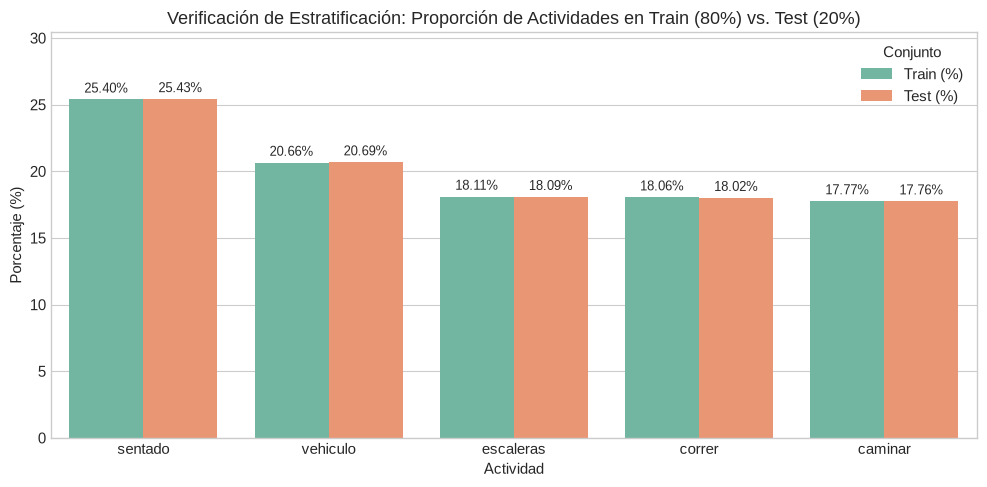

In [3]:
# División estratificada 80% entrenamiento / 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Dimensiones resultantes de la partición:")
print(f" - X_train: {X_train.shape} | y_train: {y_train.shape} ({len(X_train)/len(X)*100:.1f}%)")
print(f" - X_test:  {X_test.shape} | y_test:  {y_test.shape} ({len(X_test)/len(X)*100:.1f}%)")

# Tabla comparativa de proporciones
prop_comparison = pd.DataFrame({
    'Total (n)': y.value_counts(),
    'Total (%)': (y.value_counts(normalize=True) * 100).round(2),
    'Train (n)': y_train.value_counts(),
    'Train (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Test (n)': y_test.value_counts(),
    'Test (%)': (y_test.value_counts(normalize=True) * 100).round(2)
})
display(prop_comparison)

# Verificación automática en donde la diferencia de proporciones entre Train y Test debe ser < 0.2%
max_diff = (prop_comparison['Train (%)'] - prop_comparison['Test (%)']).abs().max()
assert max_diff < 0.2, f"Desviación excesiva en la estratificación: {max_diff:.2f}%"
print(f"\nValidación de estratificación exitosa (diferencia máxima entre Train y Test: {max_diff:.2f}%).")

# Visualización comparativa de proporciones
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = prop_comparison[['Train (%)', 'Test (%)']].reset_index().melt(
    id_vars='activity', var_name='Conjunto', value_name='Porcentaje (%)'
)

sns.barplot(data=plot_df, x='activity', y='Porcentaje (%)', hue='Conjunto', palette='Set2', ax=ax)
ax.set_title("Verificación de Estratificación: Proporción de Actividades en Train (80%) vs. Test (20%)")
ax.set_xlabel("Actividad")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, plot_df['Porcentaje (%)'].max() + 5)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

## 3. Escalamiento de Características (`StandardScaler`)

Las 24 características tienen escalas físicas distintas, por ejemplo, las varianzas como `mag_var` o `y_var` alcanzan valores mucho mayores que las medias como `x_mean`. Para estandarizar todas las variables a una misma escala, aplicamos **estandarización Z-score** mediante `StandardScaler`:

$$z = \frac{x - \mu}{\sigma}$$

donde $\mu$ es la media y $\sigma$ la desviación estándar de cada característica.

### Regla crítica para evitar fuga de datos (*Data Leakage*):
- **`fit_transform(X_train)`:** Calcula $\mu$ y $\sigma$ **exclusivamente** sobre el conjunto de entrenamiento y lo transforma.
- **`transform(X_test)`:** Aplica esos mismos parámetros ($\mu_{\text{train}}, \sigma_{\text{train}}$) sobre el conjunto de prueba, simulando datos completamente nuevos.

Escalamiento aplicado y validado correctamente:
 - X_train_scaled: (5992, 24) | Media máx abs: 2.10e-16 | Std promedio: 1.0000
 - X_test_scaled:  (1498, 24) | Media promedio: 0.0129 | Std promedio: 1.0307


,Media Original,Std Original,Media Escala,Std Escala
mag_mean,3.589,4.463,0.0,1.0001
mag_std,2.146,2.711,-0.0,1.0001
mag_var,11.955,28.219,-0.0,1.0001
y_max,7.792,10.345,0.0,1.0001


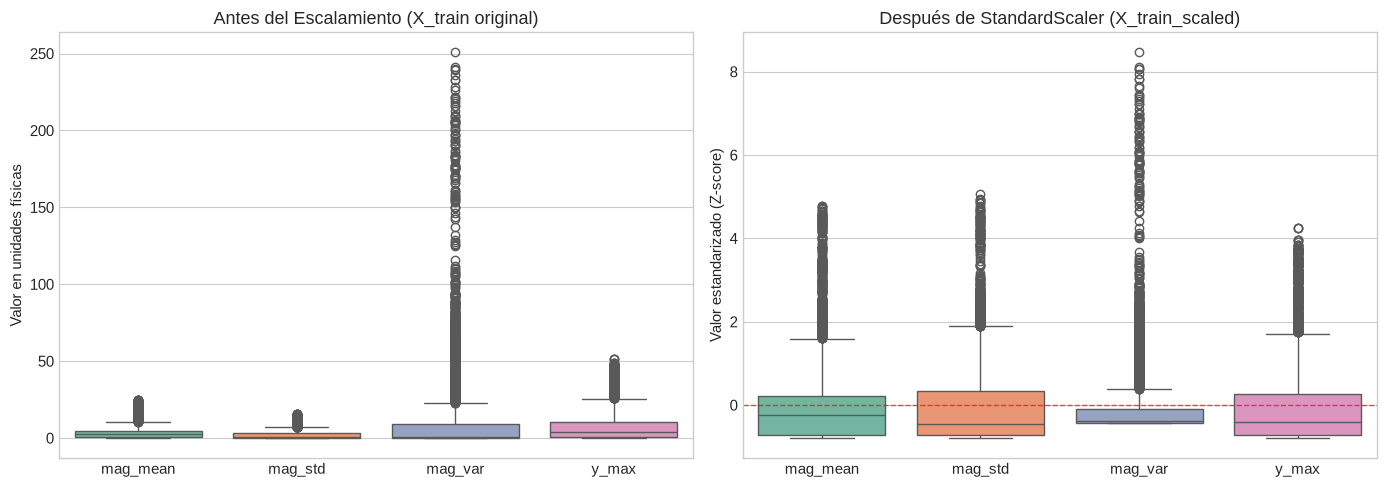

In [ ]:
# 1. Inicializar y ajustar el escalador solo con X_train
scaler = StandardScaler()
X_train_scaled_arr = scaler.fit_transform(X_train)
X_test_scaled_arr = scaler.transform(X_test)

# 2. Reconstruir DataFrames conservando nombres de columnas e índices originales
X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=FEATURE_COLS, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=FEATURE_COLS, index=X_test.index)

# 3. Verificación estadística en X_train_scaled (media ≈ 0, std ≈ 1)
train_means = X_train_scaled.mean()
train_stds = X_train_scaled.std(ddof=0)

assert np.allclose(train_means, 0, atol=1e-6), "La media de X_train_scaled no está centrada en 0."
assert np.allclose(train_stds, 1, atol=1e-6), "La desviación estándar de X_train_scaled no es 1."

print("Escalamiento aplicado y validado correctamente:")
print(f" - X_train_scaled: {X_train_scaled.shape} | Media máx abs: {train_means.abs().max():.2e} | Std promedio: {train_stds.mean():.4f}")
print(f" - X_test_scaled:  {X_test_scaled.shape} | Media promedio: {X_test_scaled.mean().mean():.4f} | Std promedio: {X_test_scaled.std(ddof=0).mean():.4f}")

# Tabla resumen de 4 características clave antes vs. después (Train)
sample_cols = ['mag_mean', 'mag_std', 'mag_var', 'y_max']
scale_summary = pd.DataFrame({
    'Media Original': X_train[sample_cols].mean().round(3),
    'Std Original': X_train[sample_cols].std().round(3),
    'Media Escala': X_train_scaled[sample_cols].mean().round(4),
    'Std Escala': X_train_scaled[sample_cols].std().round(4)
})
display(scale_summary)

# 4. Comparación visual de distribuciones antes vs. después del escalamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=X_train[sample_cols], ax=axes[0], palette='Set2')
axes[0].set_title("Antes del Escalamiento (X_train original)")
axes[0].set_ylabel("Valor en unidades físicas")

sns.boxplot(data=X_train_scaled[sample_cols], ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)
axes[1].set_title("Después de StandardScaler (X_train_scaled)")
axes[1].set_ylabel("Valor estandarizado (Z-score)")

plt.tight_layout()
plt.show()

## 4. Entrenamiento y Ajuste de Hiperparámetros — Random Forest *(Siguiente Etapa)*

Los datos quedaron preparados y validados para el entrenamiento del clasificador **Random Forest**:
- **Variables disponibles en memoria:** `X_train_scaled`, `X_test_scaled`, `y_train`, `y_test` y el objeto ajustado `scaler`.
- **Próximo paso:** Implementar el modelo base `RandomForestClassifier`, realizar búsqueda de hiperparámetros (`GridSearchCV` / `RandomizedSearchCV` con validación cruzada estratificada) y evaluar el desempeño final sobre `X_test_scaled` (Accuracy, F1-score macro, Matriz de Confusión e importancia de características).